# Simulazione conteggi

In [2]:
import numpy as np
import math
import sys
import random
import matplotlib.pyplot as plt

class SimContatore:
   # funzione di inizializzazione della classe,
   # viene chiamata quando si definisce un oggetto che 
   # appartiene alla classe. 'self' è il nome dell'oggetto
   # creato, e tutti i parametri globali di questo oggetto 
   # devono essere preceduti da 'self.'.
  def __init__(self):
    #Parametri fisici per esempio la rate in [s-1]
    self.Rt = 1   # rate tufo
    self.Rc = 5   # rate fondo cosmico
    #Caratteristiche strumento
    self.res = 0.001 #risoluzione temporale geiger [s]

  def setRt(self, Rt): 
    if (Rt > 50):
      print ("Rate troppo alta! Usa un numero tra 0.1 e 50 eventi al secondo")
      sys.exit()
    elif(Rt < 0.1):  
      print ("Rate troppo bassa! Usa un numero tra 0.1 e 50 eventi al secondo")
      sys.exit() 
    self.Rt = Rt  

  def setRc(self, Rc):
    if (Rc > 50):
      print ("Rate troppo alta! Usa un numero tra 0.1 e 50 eventi al secondo")
      sys.exit()
    elif(Rc < 0.1):  
      print ("Rate troppo bassa! Usa un numero tra 0.1 e 50 eventi al secondo")
      sys.exit()
    self.Rc = Rc

  def MisuraConteggi(self, T, n_misure, mode='tufo'):
    if mode == 'tufo': 
        R = self.Rt + self.Rc
    elif mode == 'fondo':
        R = self.Rc
    else:
        print ("Opzione errata! Usa tufo (per misura sul blocco di tufo) o 'fondo' (per misura solo fondo cosmico)")
        sys.exit()
    # print('La rate vera R = ', R)
    # myMode e' una flag che puo' servire a definire il tipo di misura
    # per esempio se faccio una misura di segnale o segnale piu' fondo

    # lo strumento accetta solo tempi al secondo tra 1 e 600
    T = round(T,1)
    if T<1 or T>6000:
        print ("La durata di una singola presa dati deve essere un numero tra 1s e 600s")
        sys.exit()  

    # liste per registrare i conteggi e i tempi di ciascun conteggio
    counts_list = []
    time_counts_list = []
    
    # assumo l'intevallo pari alla risoluzione
    # calcolo il numero di intervalli
    n = int(T / self.res)

    # calcolo la probabilita' di conteggio nell'intevallino
    p = R * self.res

    # faccio un loop sul numero di misure
    for mis in range(1,n_misure+1):
        # azzero la lista dei tempi ed il contatore di eventi
        tmp_time_counts_list = []        
        tmp_count = 0

###############################################
### simulo il comportamento di una misura
### qui devo generare in modo corretto i tempi
### a cui avvengo i conteggi
###
        # faccio il loop sugli intervallini
        for i in range(1,n+1): 
            # estraggo un numero random tra 0 e 1       
            x = random.random()
            # se il numero random e' inferiore a p, accetto l'evento
            if x<p:
                # incremento il contatore dei conteggi
                tmp_count = tmp_count + 1
                # registro il tempo a cui e' avventuto l'evento
                hit_time = round(i*self.res, 4)
                tmp_time_counts_list.append(hit_time)
        # prima di passare alla misura successiva ricopio l'evento 
        # nella lista
        counts_list.append(tmp_count)
        time_counts_list.append(np.asarray(tmp_time_counts_list))      
### esco dal loop sulle misure
################################################

    # converto tutto in mumpy-arrays    
    time_counts_np = np.asarray(time_counts_list)
    counts_np = np.asarray(counts_list)    

    
    print ("{0:d} misure ripetute di conteggio in un intervallo temporale di {1:.1f} s =".format(n_misure,T))   
    print (counts_np)
    
    return  counts_np, time_counts_np


In [3]:
# Crea l'oggetto "simulatore conteggi"
myContatore = SimContatore()

# cambio la rate del tufo
myContatore.setRc(1)

# faccio 20 misure di durata pari a 2 secondi
mycounts, mytimes = myContatore.MisuraConteggi(2, 20, 'fondo')

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (20,) + inhomogeneous part.

In [4]:
print(mytimes)

NameError: name 'mytimes' is not defined

In [5]:
mycounts, mytimes = myContatore.MisuraConteggi(2000, 1, 'fondo')

1 misure ripetute di conteggio in un intervallo temporale di 2000.0 s =
[1913]


In [6]:
mytimes

array([[3.860000e-01, 1.493000e+00, 1.904000e+00, ..., 1.998541e+03,
        1.998556e+03, 1.998956e+03]], shape=(1, 1913))

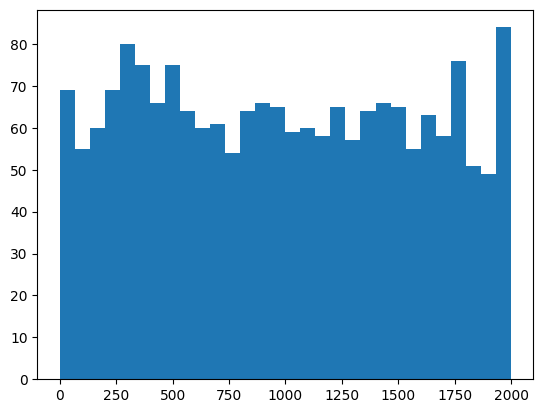

In [7]:
a,b,c = plt.hist(mytimes[0,:], bins=30)

In [ ]:
def exp(t, R):
  return R * np.exp(-R*t)

In [ ]:
def exp2(t, R):
  return R**2 * t * np.exp(-R*t)

In [15]:
import matplotlib.pyplot as plt

t = mytimes[0,2:] - mytimes[0,:-2]
a,b, c = plt.hist(t, bins=10, density=True) 

tt = np.linspace(0, 10, 100)

plt.plot(tt, exp2(tt, 1) )

NameError: name 'mytimes' is not defined

In [ ]:
plt.plot(t[1:], t[:-1],'p',markersize=.1)

In [ ]:
np.corrcoef(np.array([t[1:], t[:-1]]))

In [ ]:
plt.hist(mycounts, bins=np.arange(0,10,1))

# Simulazione pallinometro

In [4]:
# simulatore pallinometro
import numpy as np
import math
import sys
import random

# in funzione del numero di palline e delle file di chiodi
# il programma restituisce il vettore di lunghezza pari al
# numero di palline contenente in ciascuna componente la
# casella in cui e' finita la pallina.
# Con l'opzione 'partedazero=True' il numero di caselle finali
# parte da zero (quando la pallina e' caduta a sx su ogni 
# fila di chiodi) ed arriva fino al numero di file (quando e' 
# sempre caduta a dx). Quando non parte da zero, stiamo schematizzando
# con numeri negativi le volte che la pallina e' andata a sx e
# con numeri positivi le volte che va a dx. In questa configurazione
# alcune caselle non possono essere raggiunte: per esempio 
# con 3 file di chiodi non potremmo mai raggiungere la casella +-2, 
# ne la casella 0, ma solo -3, -1, 0, 1, 3.
# Per confrontarsi con la distribuzione binomiale bisogna utilizzare
# l'opzione 'partedazero=True' essendo una variabile binomiale definita
# tra 0 e nfile.

def pallinometro(npall = 1000, nfile = 15, prob = 0.5, partedazero=True):
    # inizializzo l'array delle posizioni finali
    posfin = np.repeat(-999., npall)

    # loop sulle palline
    for ipall in range(0, npall):
        pos = 0
        # loop sulle file di chiodi
        for ifile in range(0, nfile):
            # estraggo random tra 0 e 1
            x = random.random()
            # se x e' minore di prob. vado di mezzo passo a sx
            if x > prob:
                pos = pos - 1/2
            # altrimenti vado di mezzo passo a dx
            else:
                pos = pos + 1/2
        if partedazero == False:
            # se non conto le caselle da zero,
            # riporto la posizione finale in passi unitari
            posfin[ipall] = pos*2
        elif partedazero == True:
            # se conto le caselle da zero,
            # aggiunco nfile/2
            posfin[ipall] = pos + nfile/2 
            
    return posfin

In [8]:
nfile = 9
x = pallinometro(nfile=nfile, npall=3000, partedazero=True)

In [9]:
import matplotlib.pyplot as plt

(array([  2.,  54., 218., 479., 727., 780., 482., 195.,  52.,  11.]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5]),
 <BarContainer object of 10 artists>)

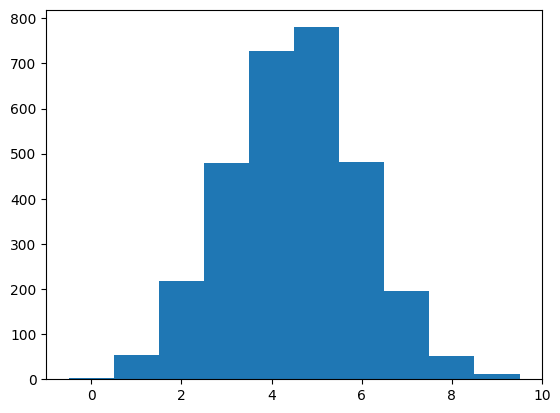

In [11]:
plt.hist(x, bins=np.arange(-0.5, nfile+1.5), density=False)

# Esempio di confronto tra istogramma del pallinometro e distribuzione binomiale

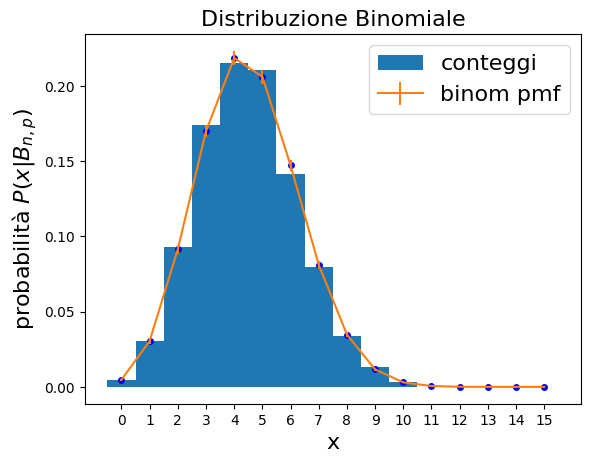

In [12]:
import matplotlib.pyplot as plt
from scipy.stats import binom
nfile = 15
npall = 10000
prob = 0.3

pall = pallinometro(nfile=nfile, npall=npall, partedazero=True, prob=prob)

plt.hist(pall, bins=np.arange(-0.5, nfile+1.5), density=True, label='conteggi')

x = np.arange(0, nfile+1)

# grafico della pmf
plt.plot(x, binom.pmf(x, nfile, prob), 'bo', ms=4)

plt.errorbar(x, binom.pmf(x, nfile, prob), yerr = np.sqrt(binom.pmf(x, nfile, prob)/npall),  ms=4,
         label='binom pmf')

plt.title('Distribuzione Binomiale',  fontsize=16)
plt.xlabel("x", fontsize=16)
plt.ylabel("probabilità $P(x| B_{n,p})$", fontsize=16)
plt.legend( fontsize=16)
t = plt.xticks(x)


In [ ]:
 # simulatore conteggi compatto
 
 def poissonProcess(rA = 1., rS = 1., rC= 1., T = 10., nmis = 10, conf = 'O', res = 0.0001):
  R = 0
  if conf == 'O':
    R = rA + rC
  elif conf == 'V':
    R = rA + rC / 2
  elif conf == 'S':
    R = rA + rC + rS
  else:
    raise Exception("Configurazione ignota.")
  
  misure, tempi = [], []
  for i in range(nmis):
    hits = np.random.choice(np.array([0,1]), p = np.array([1-R*res, R*res]), size = int(T/res))
    misure.append(np.sum(hits))
    if len(hits) ==0:
      tempi.append(-1) # nel caso non avessi hits, metto il tempo = -1
                       # per convenzione e per non appendere un array vuoto
    else:
      tempi.append(np.where(hits == 1)[0] * res)
  return misure, tempi

In [ ]:
# simulatore pallinometro compatto

def pallinom(balls = 10, lines = 15, prob = 0.5, partedazero = True):
  casella = np.zeros(balls)
  for i in range(balls):
    traiettoria = np.random.choice(np.array([-0.5, 0.5]), p = np.array([1-prob, prob]), size = lines)
    if partedazero:
      casella[i] = np.sum(traiettoria) + lines/2.
    else:
      casella[i] = np.sum(traiettoria)*2
  return casella

In [ ]:


import numpy as np
import math
import sys
import random


def MisuraConteggi(T, n_misure, mode='tufo', Rt=1, Rc=5):

# risoluzione temporale del contatore
  res = 0.001

# possibilità di combinare sorgenti diverse  
  if mode == 'tufo': 
        R = Rt + Rc
  elif mode == 'fondo':
        R = Rc
  else:
        print ("Opzione errata! Usa tufo (per misura sul blocco di tufo) o 'fondo' (per misura solo fondo cosmico)")
        sys.exit()
        print('La rate vera R = ', R)

  # lo strumento accetta solo tempi al secondo tra 1 e 600
  T = round(T,1)
  if T<1 or T>600:
        print ("La durata di una singola presa dati deve essere un numero tra 1s e 600s")
        sys.exit()  

 # liste per registrare i conteggi e i tempi di ciascun conteggio
  counts_list = []
  time_counts_list = []
    
  # assumo l'intevallo pari alla risoluzione
  # calcolo il numero di intervalli
  n = int(T / res)

  # calcolo la probabilita' di conteggio nell'intevallino
  p = R * res

  if (p > 0.01): 
    print('Lo strumento non ha una risoluzione temporale per osservare eventi con rate cosi elevata')
    sys.exit() 

    # faccio un loop sul numero di misure
  for mis in range(1, n_misure+1):
    # azzero la lista dei tempi ed il contatore di eventi
    tmp_time_counts_list = []        
    tmp_count = 0

###############################################
### simulo il comportamento di una misura
### qui devo generare in modo corretto i tempi
### a cui avvengo i conteggi
###
    # faccio il loop sugli intervallini
    # !!!!! DEVE ESSERE IMPLEMENTATO  !!!!!
    for i in range(1, n+1):     
    # se l'evento accade, registro il tempo come:
      rrr = random.random()
      if (rrr < p): 
      #if(i == 7): # opportuno indice che rappresenta l'intervallino 
        # in cui accade un evento
        hit_time = round(i*res, 4) # misuro il tempo come 
                                   # i * Delta t (in questo caso la risoluzione)
        tmp_time_counts_list.append(hit_time) # metto il tempo dell'evento in
   
    # esco dal loop sugli intervallini

    # conto gli eventi, e copio i risutati in una lista contenente
    # le varie misure
    counts_list.append(len(tmp_time_counts_list))
    # copio tutti i tempi degli eventi (un array) in una lista contentente
    # le varie misure

    time_counts_list.append(np.asarray(tmp_time_counts_list))      
### esco dal loop sulle misure
################################################

    # converto tutto in mumpy-arrays    
  time_counts_np = np.asarray(time_counts_list)
  counts_np = np.asarray(counts_list)    

    
  print ("{0:d} misure ripetute di conteggio in un intervallo temporale di {1:.1f} s =".format(n_misure,T))   
  print (counts_np)
  print (R)  
  return  counts_np, time_counts_np

In [ ]:
mycounts, mytimes = MisuraConteggi(T=1, n_misure=10, mode='tufo')

In [ ]:
mytimes

In [ ]:
plt.hist(mytimes)